[([[0, np.int32(8)], [72, np.int32(8)], [72, np.int32(100)], [0, np.int32(100)]], 'K', np.float64(0.9999510055821226))]


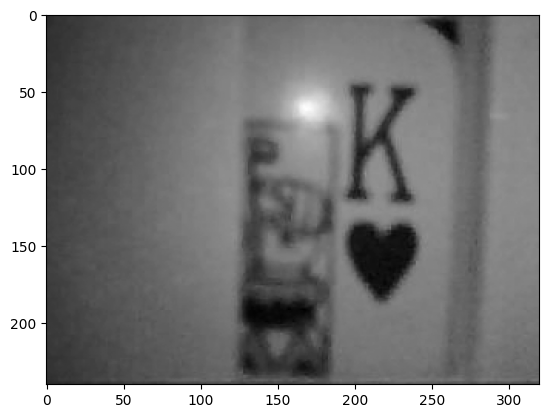

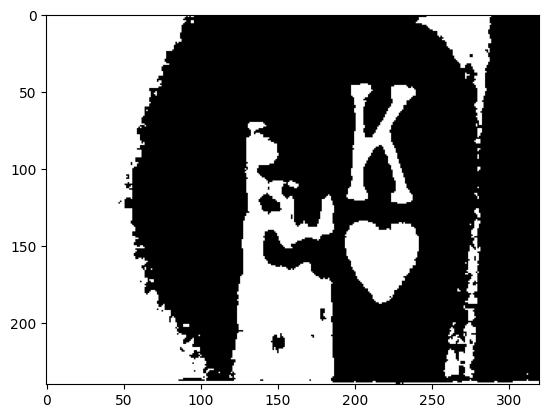

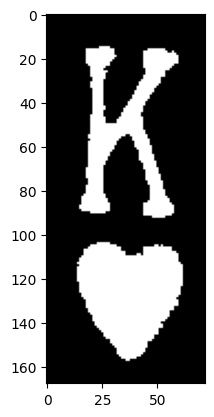

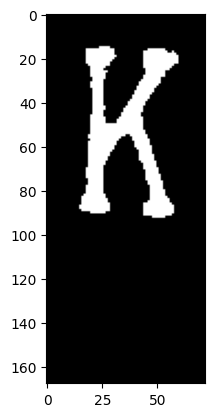

In [216]:
import easyocr
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plot
import math

reader=easyocr.Reader(['en'])
im=cv.imread("k.jpg")
ig=cv.cvtColor(im,cv.COLOR_RGB2GRAY)


# ig = cv.filter2D(ig, -1, kernel)
# ig=cv.blur(ig,(11,11))
plot.figure()
plot.imshow(ig,cmap="gray")
# ig=cv.adaptiveThreshold(ig,255,cv.ADAPTIVE_THRESH_MEAN_C,cv.THRESH_BINARY_INV,7,4)
ret,ig=cv.threshold(ig,0,255,cv.THRESH_BINARY_INV+cv.THRESH_OTSU)
plot.figure()
plot.imshow(ig,cmap="gray")
# ia=ig[:150,150:]
thresh=np.zeros(ig.shape,dtype=np.uint8)
# kernel = np.ones((5,5),np.uint8)
cnts,x = cv.findContours(ig, cv.RETR_LIST, cv.CHAIN_APPROX_SIMPLE)

cntsAreas=[cv.contourArea(i) for i in cnts]
mean=sum(cntsAreas)/len(cnts)
std=math.sqrt((sum([(i-mean)**2 for i in cntsAreas]))/len(cnts))
minX=10000
minY=10000
maxX=0
maxY=0
for c in cnts:
    area = cv.contourArea(c)
    # print(area)
    if area < mean+std and area>mean:
        x,y,w,h=cv.boundingRect(c)
        minX=min(minX,x)-10
        minY=min(minY,y)-10
        maxX=max(maxX,minX+w+20)
        maxY=max(maxY,minY+h+20)

        ap=cv.approxPolyDP(c,0.001*cv.arcLength(c,True),True)
        cv.drawContours(thresh,[ap],-1,(255,255,255),-1)
# ig=cv.dilate(ig,kernel,iterations=2)

# ig=cv.morphologyEx(ig, cv.MORPH_CLOSE, kernel,iterations=1)
# ig=ig[40:,60:]
minY=max(30,minY)
minX=max(180,minX)
thresh=thresh[minY:maxY,minX:maxX]

plot.figure()
plot.imshow(thresh,cmap="gray")


cnts,x = cv.findContours(thresh, cv.RETR_LIST, cv.CHAIN_APPROX_SIMPLE)

cntsAreas=[(cv.contourArea(i),i) for i in cnts]
# print(len(cntsAreas))
cc = max(cntsAreas, key=lambda x: x[0])[1]
# print(cc)
test=np.zeros(thresh.shape,dtype=np.uint8)
ap=cv.approxPolyDP(cc,0.001*cv.arcLength(cc,True),True)
cv.drawContours(test,[ap],-1,(255,255,255),-1)
test=thresh-test

thresh=np.zeros(thresh.shape,dtype=np.uint8)
cnts,x = cv.findContours(test, cv.RETR_LIST, cv.CHAIN_APPROX_SIMPLE)

cntsAreas=[(cv.contourArea(i),i) for i in cnts]
# print(len(cntsAreas))
cc = max(cntsAreas, key=lambda x: x[0])[1]

ap=cv.approxPolyDP(cc,0.001*cv.arcLength(cc,True),True)
cv.drawContours(thresh,[ap],-1,(255,255,255),-1)


plot.figure()
plot.imshow(thresh,cmap="gray")

a=reader.readtext(thresh,allowlist='123456789KJQA')
print(a)

# Create SURF object. You can specify params here or later.
# Here I set Hessian Threshold to 400
# ig=cv.Canny(ig,100,200)
